In [1]:
from google.colab import files
uploaded = files.upload()

Saving results share.zip to results share.zip


In [2]:
import zipfile
import os

zip_name = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('/content/parking_data')

print("ZIP file extracted successfully!")
print(os.listdir('/content/parking_data/results'))

ZIP file extracted successfully!
['zone_analysis.csv', 'violation_analysis.csv', 'electric_vehicle_analysis.csv', 'occupancy_summary.csv', 'occupancy_analysis.csv', 'vehicle_analysis.csv', 'payment_analysis.csv', 'correlation_analysis.csv', 'statistical_summary.csv', 'entry_time_analysis.csv']


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

path = '/content/parking_data/results'

occupancy = pd.read_csv(path + '/occupancy_analysis.csv')
entry = pd.read_csv(path + '/entry_time_analysis.csv')
payment = pd.read_csv(path + '/payment_analysis.csv')
vehicle = pd.read_csv(path + '/vehicle_analysis.csv')
zone = pd.read_csv(path + '/zone_analysis.csv')
electric = pd.read_csv(path + '/electric_vehicle_analysis.csv')
violation = pd.read_csv(path + '/violation_analysis.csv')
correlation = pd.read_csv(path + '/correlation_analysis.csv', index_col=0)

print("All datasets loaded successfully!")
print("Occupancy data:")
print(occupancy.head())

All datasets loaded successfully!
Occupancy data:
  Unnamed: 0  Record_Count  Percentage
0   Occupied           550        55.0
1     Vacant           450        45.0


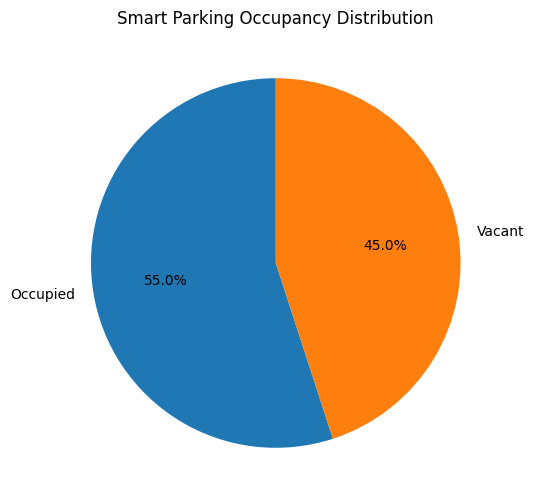

In [4]:
plt.figure(figsize=(6, 6))

plt.pie(
    occupancy['Record_Count'],
    labels=occupancy['Unnamed: 0'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Smart Parking Occupancy Distribution')
plt.show()

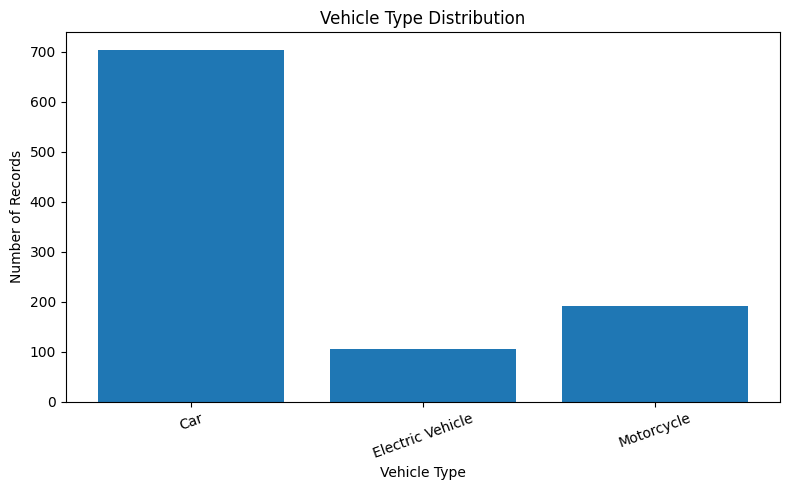

In [5]:
plt.figure(figsize=(8, 5))

plt.bar(vehicle['Vehicle_Type'], vehicle['Total_Records'])

plt.title('Vehicle Type Distribution')
plt.xlabel('Vehicle Type')
plt.ylabel('Number of Records')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

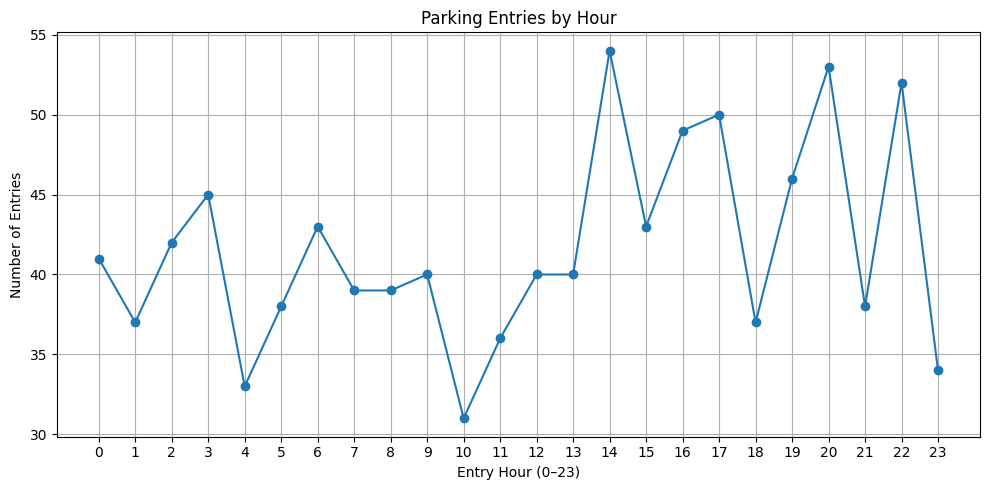

In [6]:
entry = entry.sort_values('Entry_Time')

plt.figure(figsize=(10, 5))

plt.plot(
    entry['Entry_Time'],
    entry['Total_Entries'],
    marker='o'
)

plt.title('Parking Entries by Hour')
plt.xlabel('Entry Hour (0–23)')
plt.ylabel('Number of Entries')
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

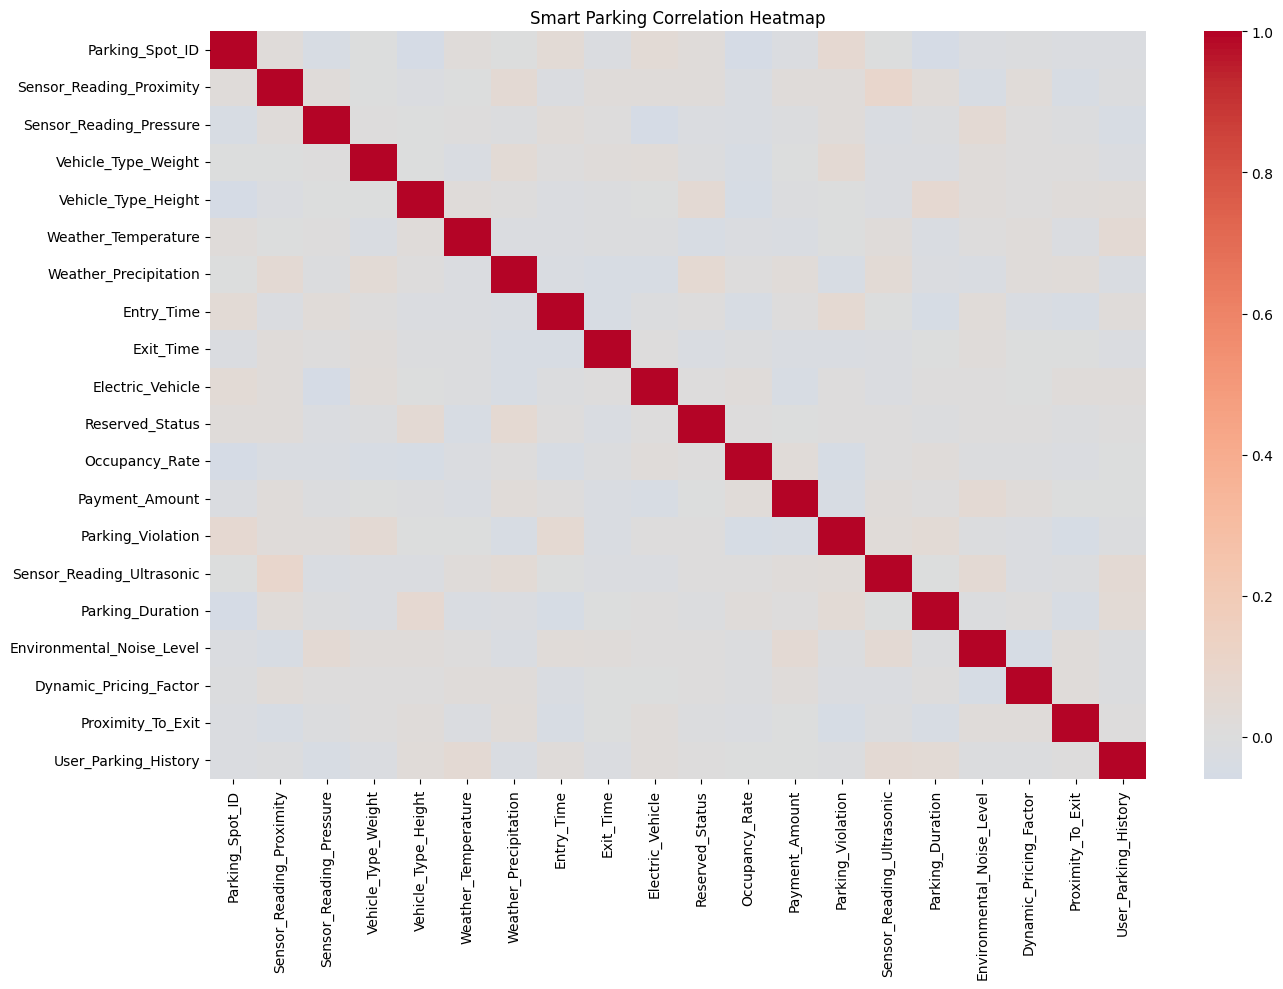

In [8]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation.select_dtypes(include='number'),
    cmap='coolwarm',
    center=0
)

plt.title('Smart Parking Correlation Heatmap')
plt.tight_layout()
plt.show()

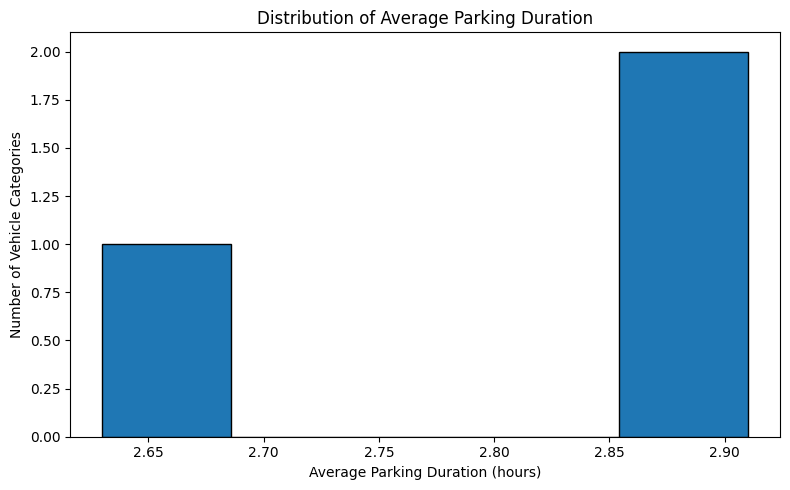

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(
    vehicle['Average_Duration'],
    bins=5,
    edgecolor='black'
)

plt.title('Distribution of Average Parking Duration')
plt.xlabel('Average Parking Duration (hours)')
plt.ylabel('Number of Vehicle Categories')
plt.tight_layout()
plt.show()

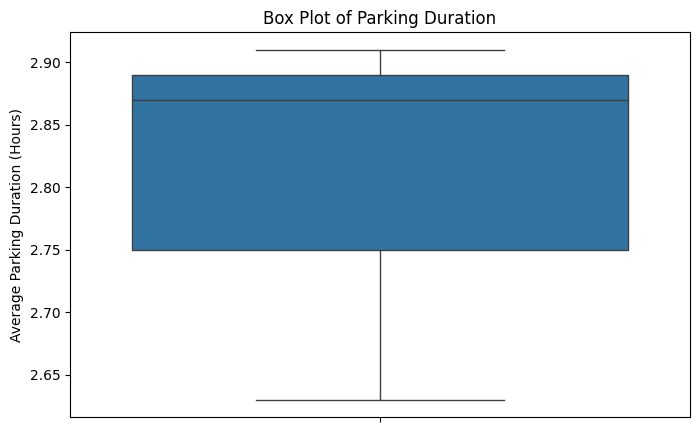

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(y=vehicle['Average_Duration'])

plt.title('Box Plot of Parking Duration')
plt.ylabel('Average Parking Duration (Hours)')

plt.show()